In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

In [3]:
exec_file = pd.ExcelFile('D:\\Data science\\Assignments\\Questions\\Random Forest\\Random Forest\\glass.xlsx')
print(exec_file.sheet_names)

['Description', 'glass']


In [4]:
df = exec_file.parse('glass')
df

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.00,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.00,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.00,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.00,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.00,0.0,1
...,...,...,...,...,...,...,...,...,...,...
209,1.51623,14.14,0.00,2.88,72.61,0.08,9.18,1.06,0.0,7
210,1.51685,14.92,0.00,1.99,73.06,0.00,8.40,1.59,0.0,7
211,1.52065,14.36,0.00,2.02,73.42,0.00,8.44,1.64,0.0,7
212,1.51651,14.38,0.00,1.94,73.61,0.00,8.48,1.57,0.0,7


### EDA

In [5]:
display(df.head())
display(df.info())
display(df.isnull().sum())
df

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB


None

RI      0
Na      0
Mg      0
Al      0
Si      0
K       0
Ca      0
Ba      0
Fe      0
Type    0
dtype: int64

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.00,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.00,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.00,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.00,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.00,0.0,1
...,...,...,...,...,...,...,...,...,...,...
209,1.51623,14.14,0.00,2.88,72.61,0.08,9.18,1.06,0.0,7
210,1.51685,14.92,0.00,1.99,73.06,0.00,8.40,1.59,0.0,7
211,1.52065,14.36,0.00,2.02,73.42,0.00,8.44,1.64,0.0,7
212,1.51651,14.38,0.00,1.94,73.61,0.00,8.48,1.57,0.0,7


No cleaning required data good to be trined  
but requires preprocess

### visulization

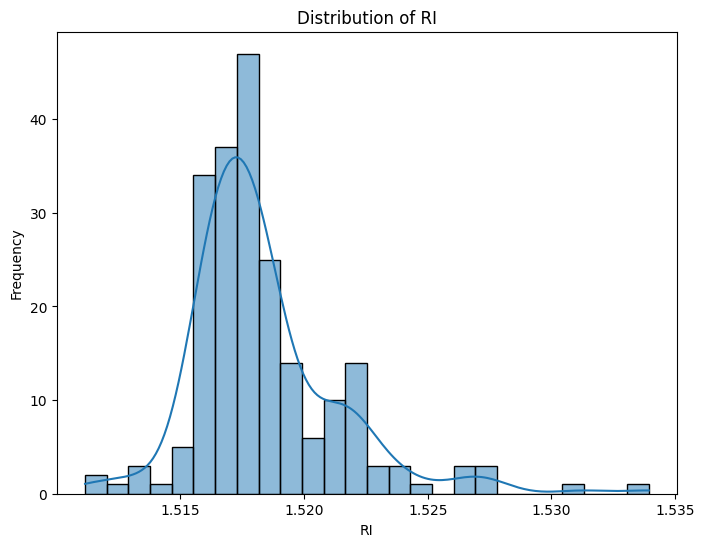

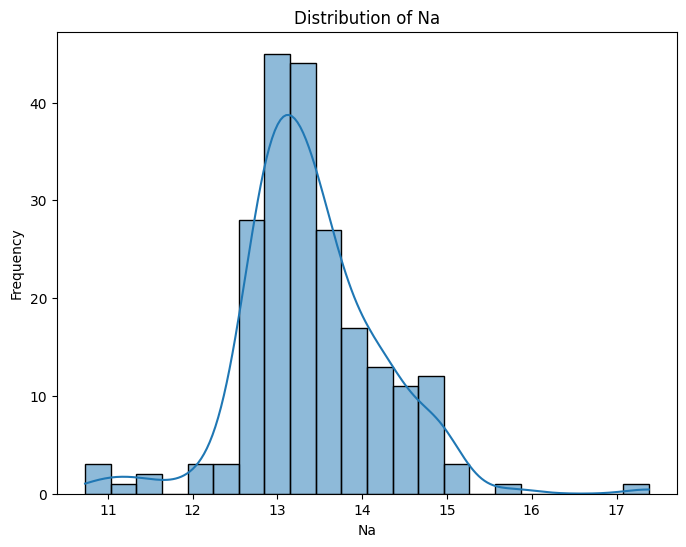

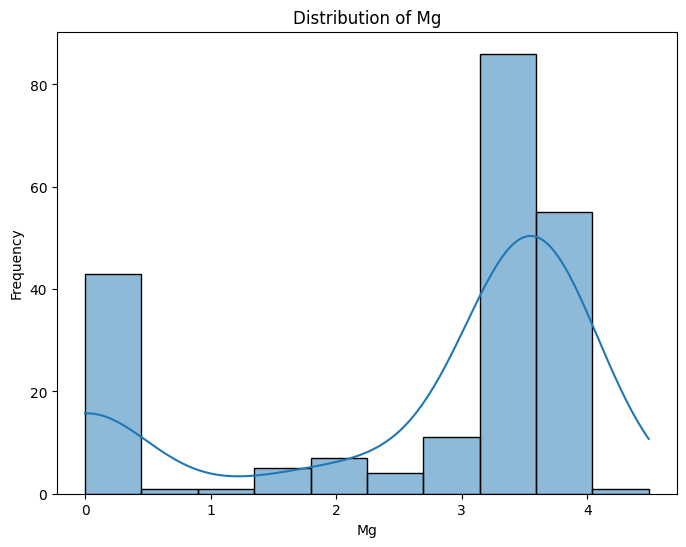

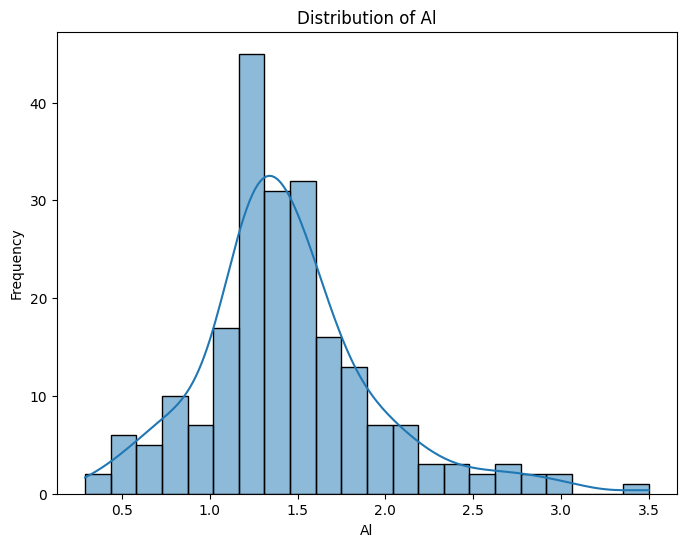

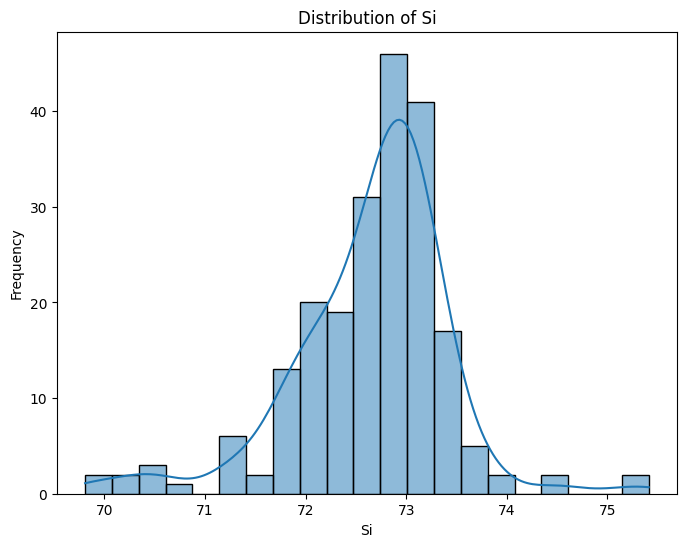

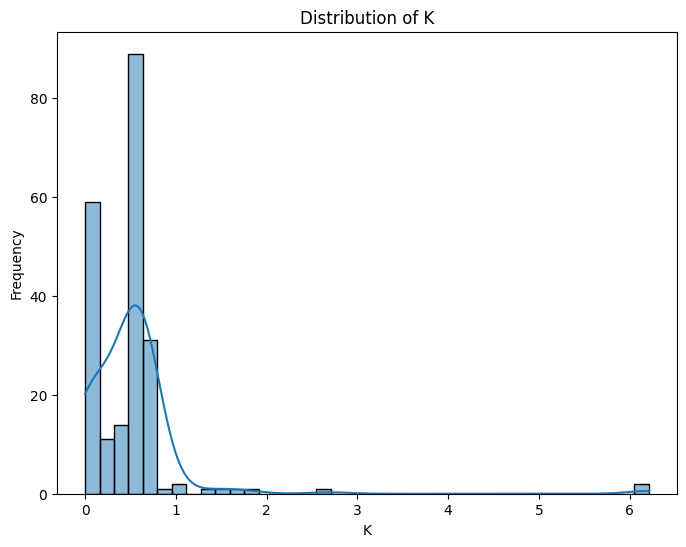

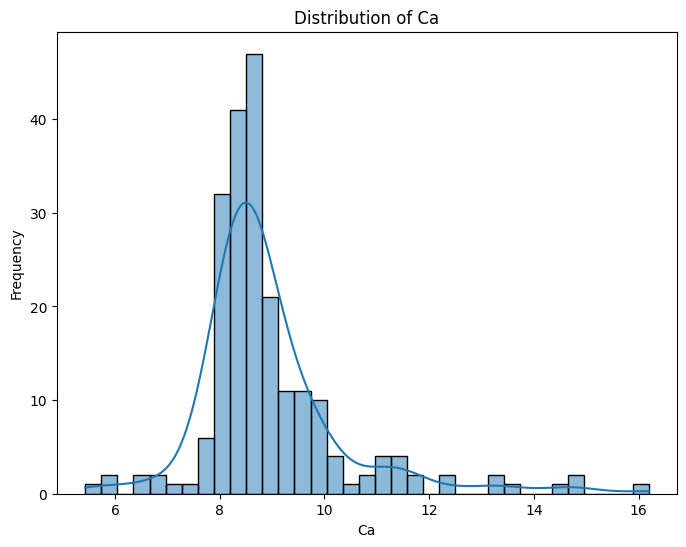

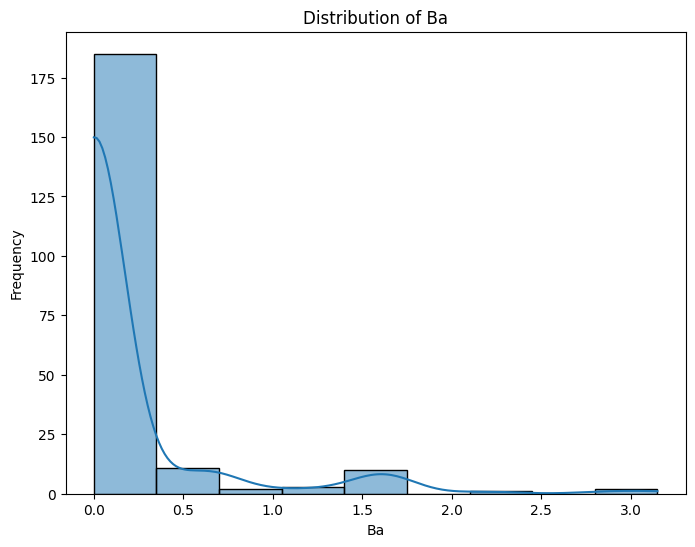

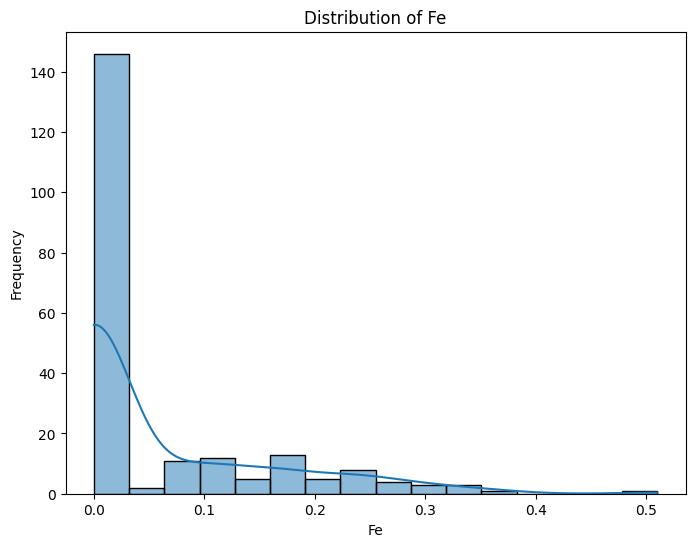

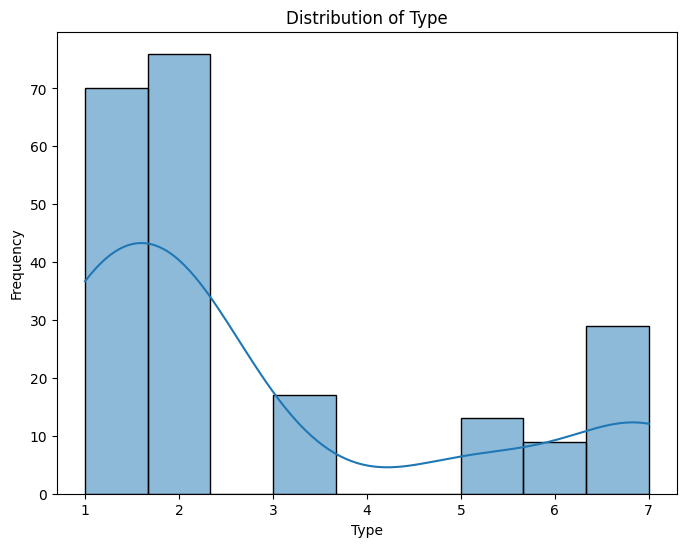

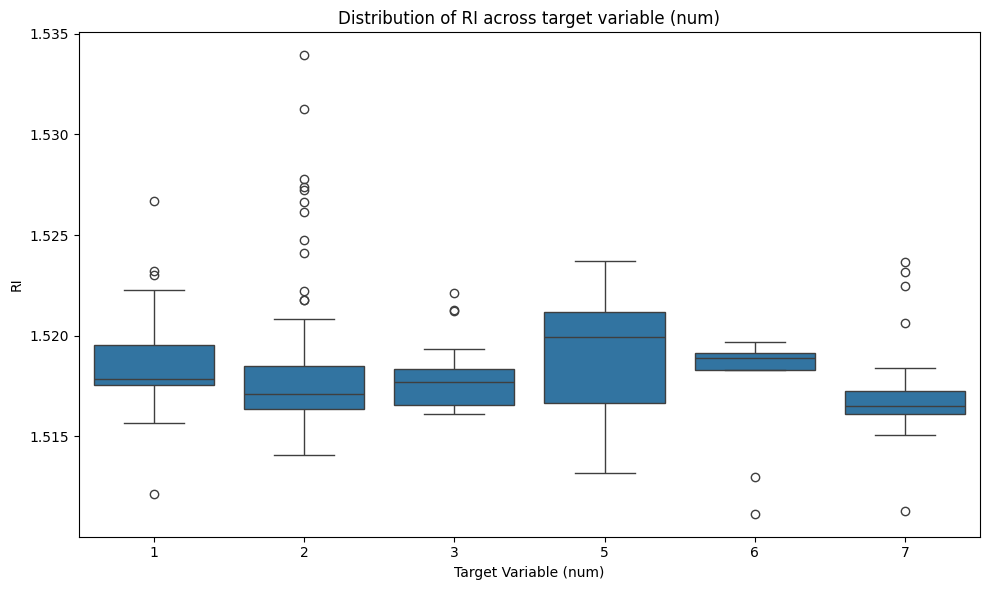

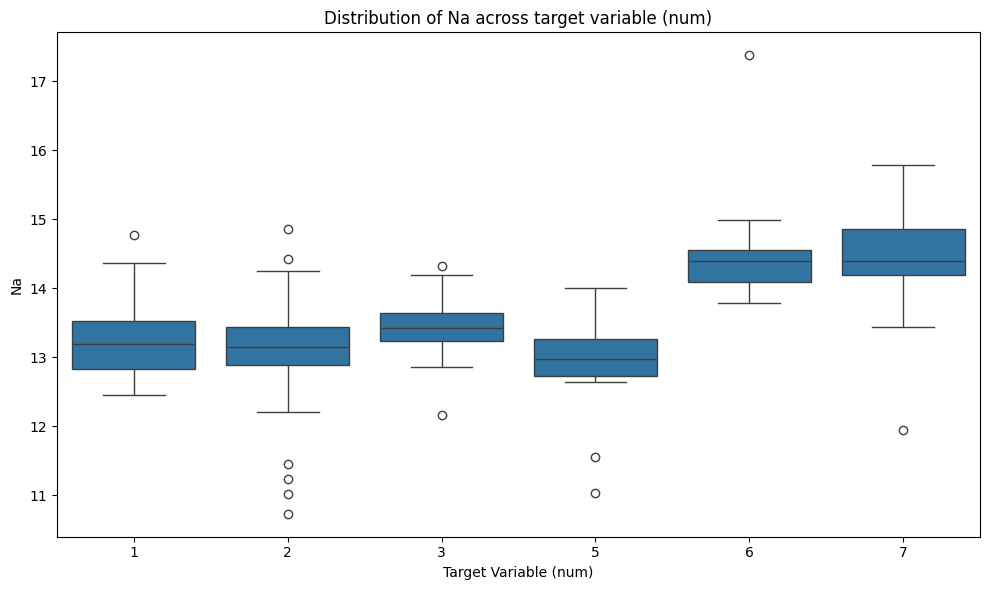

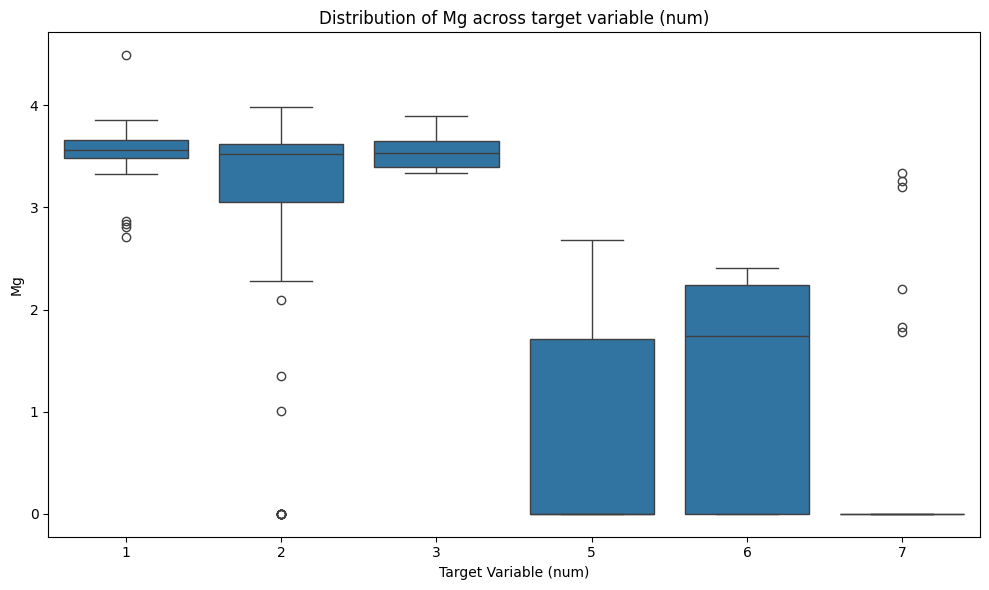

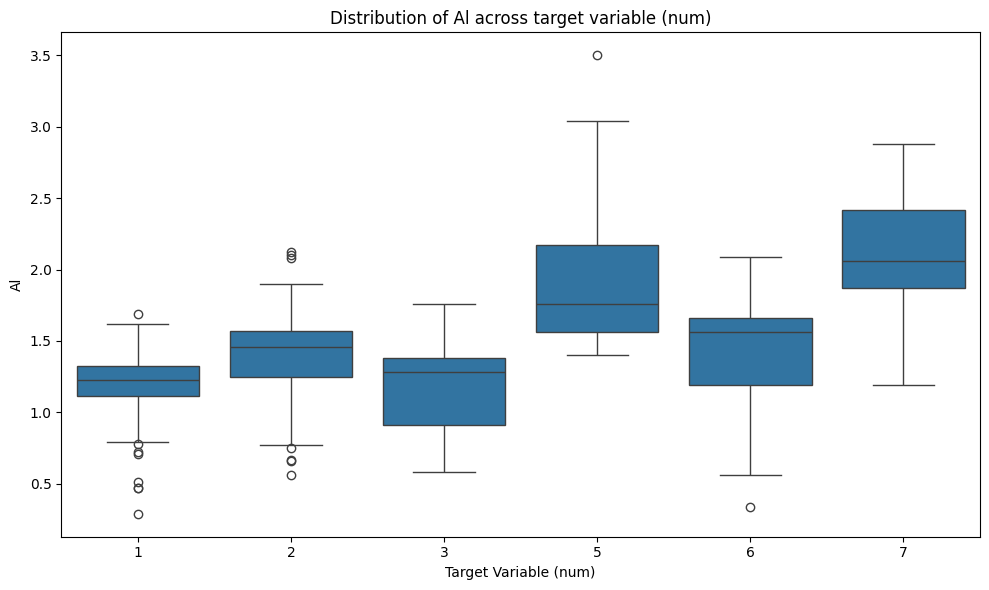

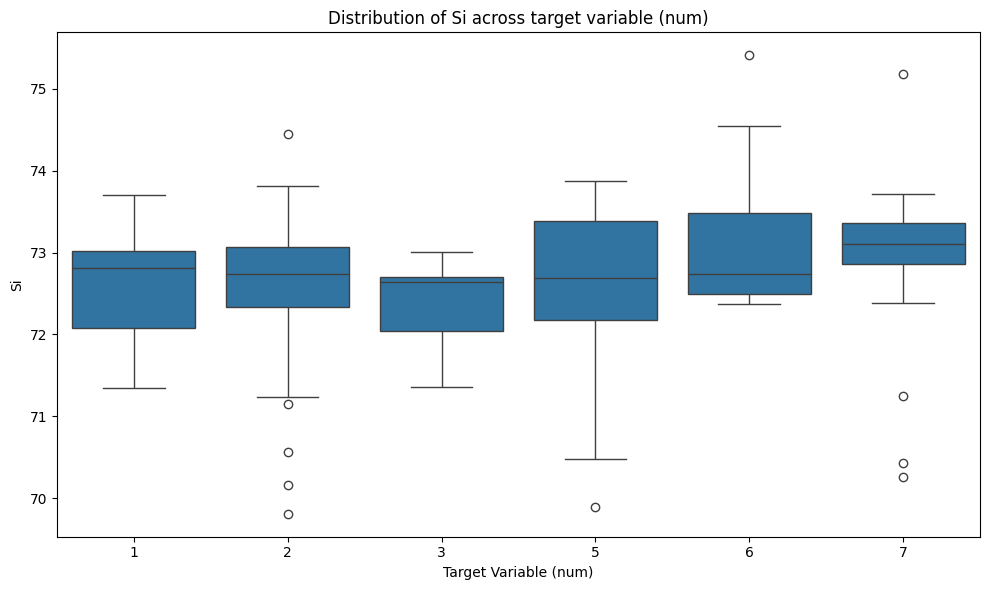

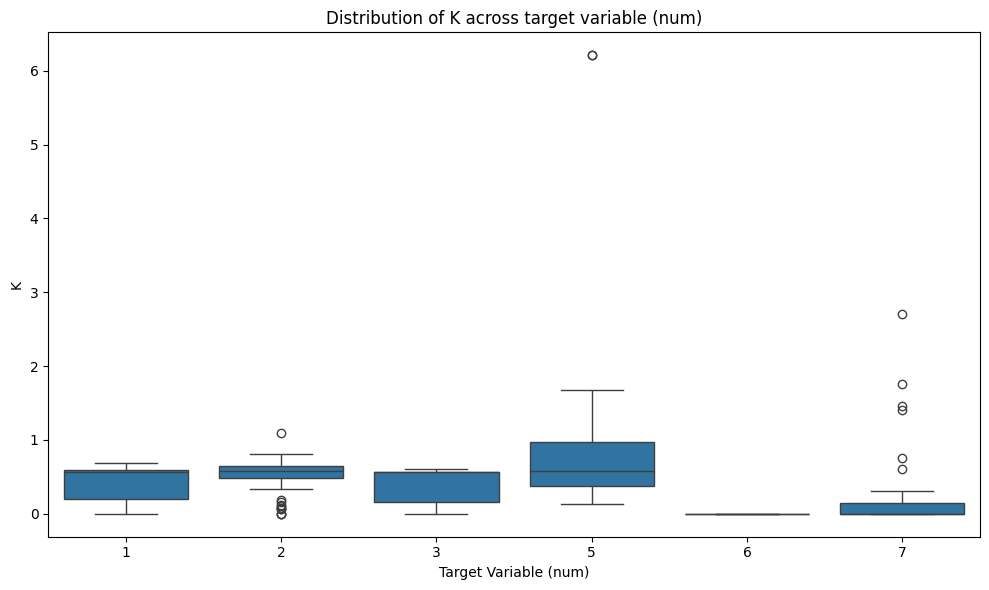

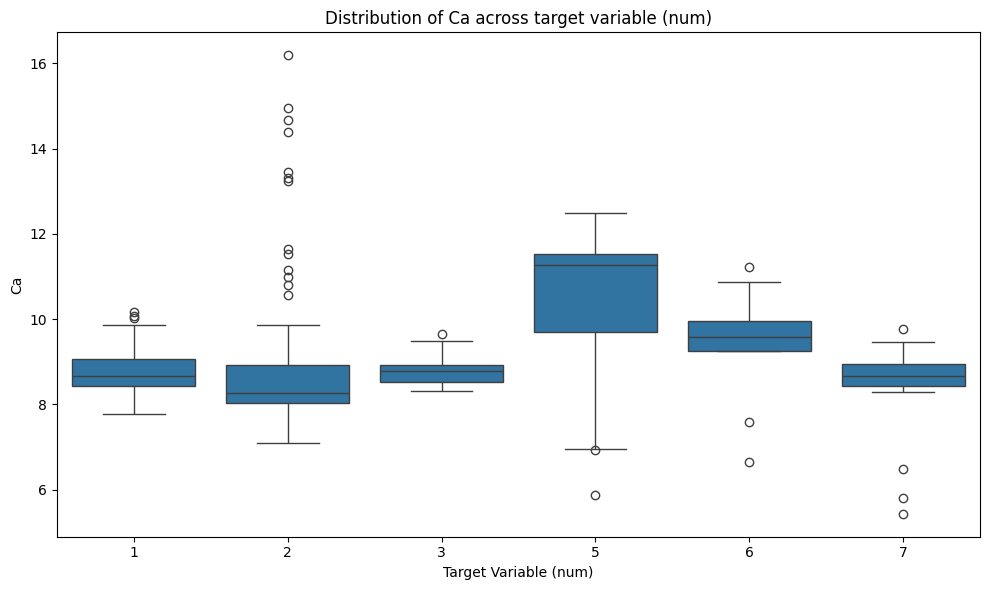

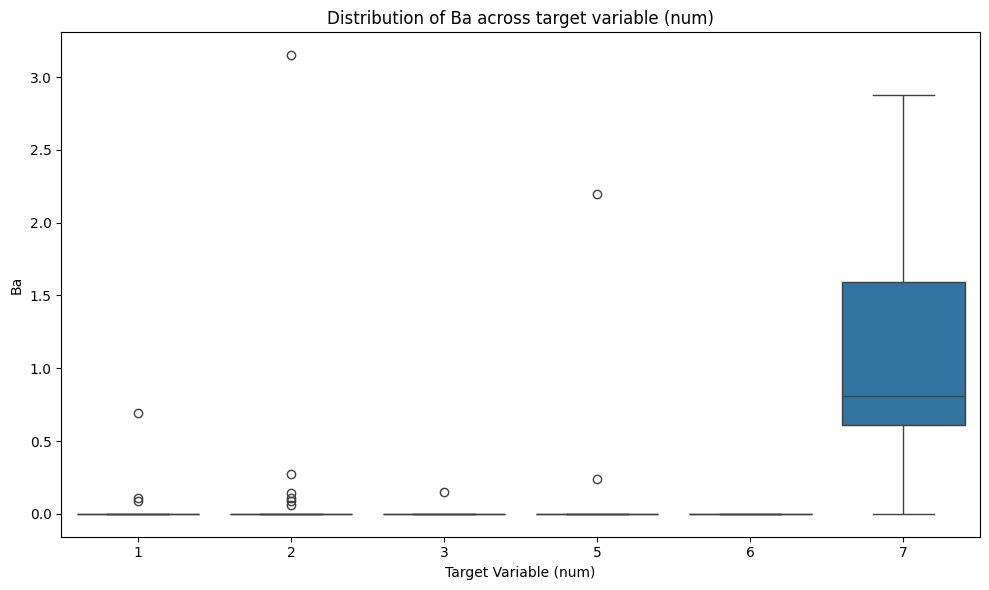

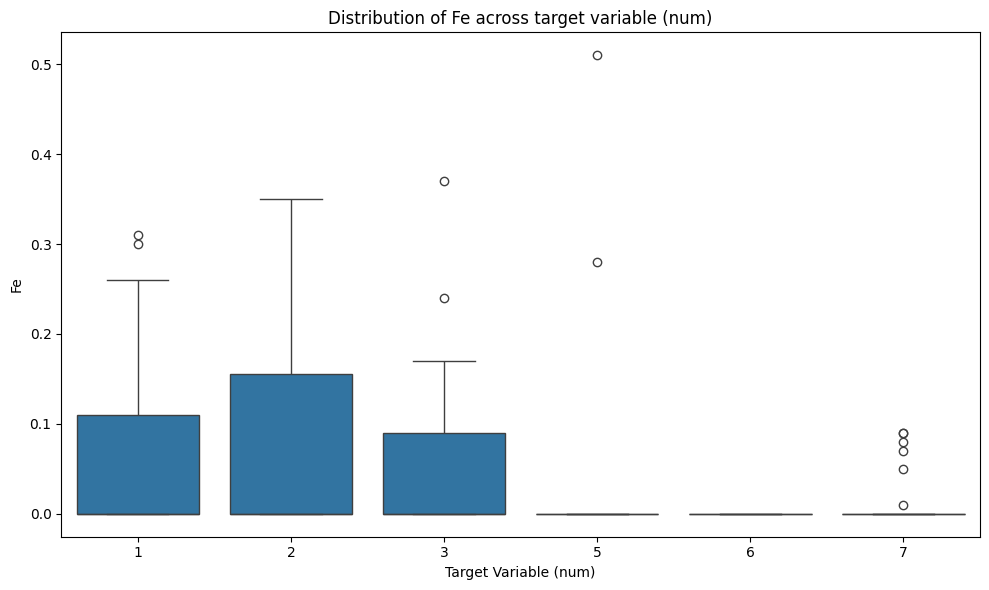

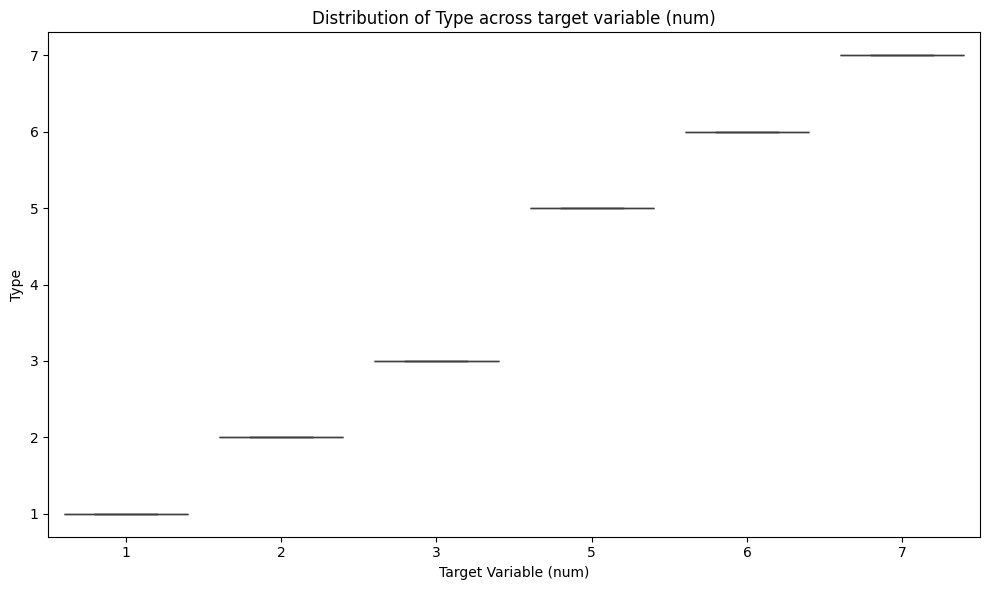

In [6]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = df.select_dtypes(include=['object', 'bool']).columns

for col in numerical_cols:
    plt.figure(figsize=(8, 6))
    sns.histplot(df[col].dropna(), kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

for col in categorical_cols:
    plt.figure(figsize=(10, 6))
    sns.countplot(data=df, y=col, order=df[col].value_counts().index)
    plt.title(f'Distribution of {col}')
    plt.xlabel('Count')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

for col in df.columns:
    plt.figure(figsize=(10, 6))
    sns.boxplot(data=df, x='Type', y=col)
    plt.title(f'Distribution of {col} across target variable (num)')
    plt.xlabel('Target Variable (num)')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

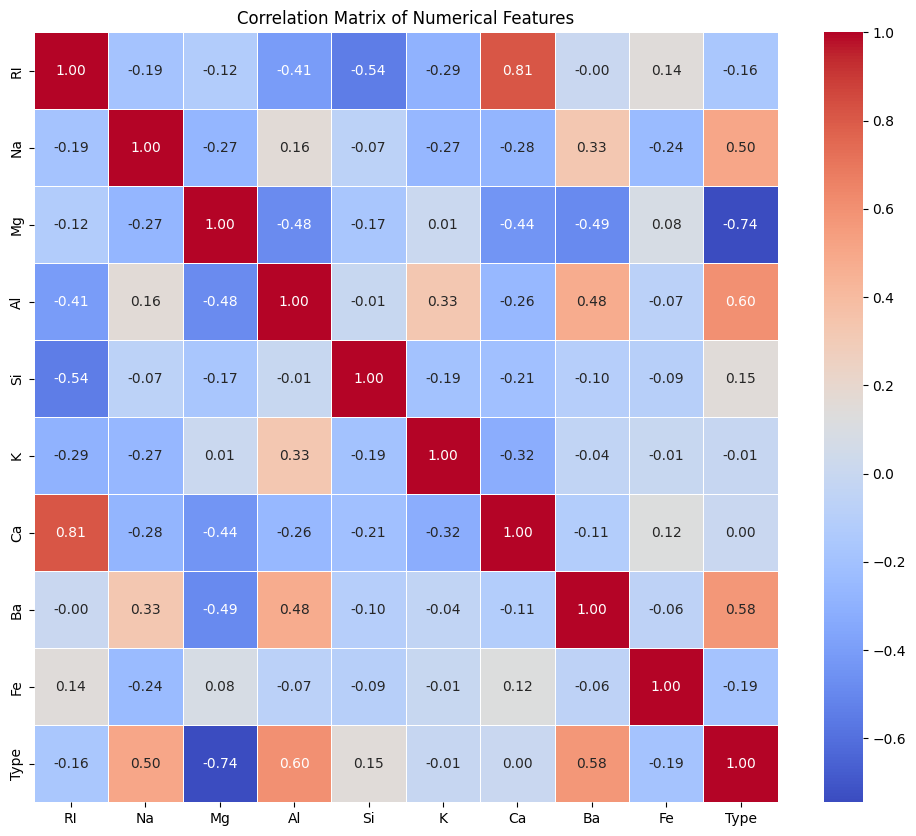

In [7]:
plt.figure(figsize=(12, 10))
correlation_matrix = df[numerical_cols].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

### preprocessing

In [8]:
# Define features and target before scaling
X = df.drop(['Type'], axis=1)
y = df['Type']

# Split before scaling to avoid data leakage
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=0.3, random_state=42)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Model Fitting (Random Forest)

In [9]:
from sklearn.ensemble import RandomForestClassifier

rf_model_scaled = RandomForestClassifier(random_state=42)
rf_model_scaled.fit(X_train_scaled, Y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [10]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Predict on test set only
y_pred_scaled = rf_model_scaled.predict(X_test_scaled)

accuracy_scaled = accuracy_score(Y_test, y_pred_scaled)
precision_scaled = precision_score(Y_test, y_pred_scaled, average='weighted')
recall_scaled = recall_score(Y_test, y_pred_scaled, average='weighted')
f1_scaled = f1_score(Y_test, y_pred_scaled, average='weighted')

print(f'Scaled Accuracy: {accuracy_scaled:.4f}')
print(f'Scaled Precision: {precision_scaled:.4f}')
print(f'Scaled Recall: {recall_scaled:.4f}')
print(f'Scaled F1-score: {f1_scaled:.4f}')

Scaled Accuracy: 0.7692
Scaled Precision: 0.7662
Scaled Recall: 0.7692
Scaled F1-score: 0.7601


### Model Fitting (Bagging and Boosting)

In [11]:
from sklearn.ensemble import BaggingClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier

# Bagging with Decision Tree as base estimator
bagging_model = BaggingClassifier(DecisionTreeClassifier(), random_state=42)
bagging_model.fit(X_train_scaled, Y_train)

# Gradient Boosting
boosting_model = GradientBoostingClassifier(random_state=42)
boosting_model.fit(X_train_scaled, Y_train)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


### Evaluation of Bagging and Boosting Models

In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Predict on test set
y_pred_bagging = bagging_model.predict(X_test_scaled)
y_pred_boosting = boosting_model.predict(X_test_scaled)

# Evaluate Bagging model
accuracy_bagging = accuracy_score(Y_test, y_pred_bagging)
precision_bagging = precision_score(Y_test, y_pred_bagging, average='weighted')
recall_bagging = recall_score(Y_test, y_pred_bagging, average='weighted')
f1_bagging = f1_score(Y_test, y_pred_bagging, average='weighted')

print(f'Bagging Accuracy: {accuracy_bagging:.4f}')
print(f'Bagging Precision: {precision_bagging:.4f}')
print(f'Bagging Recall: {recall_bagging:.4f}')
print(f'Bagging F1-score: {f1_bagging:.4f}')

print("-" * 20)

# Evaluate Boosting model
accuracy_boosting = accuracy_score(Y_test, y_pred_boosting)
precision_boosting = precision_score(Y_test, y_pred_boosting, average='weighted')
recall_boosting = recall_score(Y_test, y_pred_boosting, average='weighted')
f1_boosting = f1_score(Y_test, y_pred_boosting, average='weighted')

print(f'Boosting Accuracy: {accuracy_boosting:.4f}')
print(f'Boosting Precision: {precision_boosting:.4f}')
print(f'Boosting Recall: {recall_boosting:.4f}')
print(f'Boosting F1-score: {f1_boosting:.4f}')

Bagging Accuracy: 0.7538
Bagging Precision: 0.7843
Bagging Recall: 0.7538
Bagging F1-score: 0.7404
--------------------
Boosting Accuracy: 0.8000
Boosting Precision: 0.8224
Boosting Recall: 0.8000
Boosting F1-score: 0.7888


### interview questions

### 1Q Explain Bagging and Boosting methods. How is it different from each other.|
Bagging (Bootstrap Aggregating)

1 Bagging is an ensemble technique that aims to reduce variance and improve the stability and accuracy of machine learning algorithms.  
- It involves training multiple models on different subsets of the original dataset. These subsets are created by bootstrapping, which means randomly sampling the data with replacement.  
- For classification tasks, the final prediction is typically made by taking a majority vote of the predictions from the individual models. For regression tasks, the predictions are averaged.
- A common example of a bagging algorithm is the Random Forest, which uses decision trees as the base estimators.
Boosting

2 Boosting is another ensemble technique that aims to improve the accuracy of models by sequentially building models that learn from the errors of the previous models.
- It starts with a base model and then iteratively adds new models that focus on the instances that were misclassified by the previous models.
- Each new model is weighted based on its performance, and the final prediction is a weighted combination of the predictions from all the models.
- Boosting algorithms are generally more prone to overfitting than bagging algorithms, but they can achieve higher accuracy if properly tuned.
- Examples of boosting algorithms include AdaBoost, Gradient Boosting, and XGBoost.

### 2Q Explain how to handle imbalance in the data.
Here are some common techniques to handle imbalanced data:

1) Resampling Techniques:
- Oversampling the minority class: This involves creating synthetic samples of the minority class to increase its representation in the dataset. Techniques like SMOTE (Synthetic Minority Over-sampling Technique) are commonly used.
- Undersampling the majority class: This involves reducing the number of samples in the majority class. This can be done randomly or by using more sophisticated techniques to select representative samples.
2) Using Different Evaluation Metrics: Accuracy can be misleading in imbalanced datasets. It's important to use metrics that are more informative for imbalanced data, such as:  
- Precision and Recall: These metrics focus on the performance of the model on the minority class.  
- F1-score: This is the harmonic mean of precision and recall and provides a balanced measure of performance.  
- Area Under the ROC Curve (AUC-ROC): This metric measures the ability of the model to distinguish between the classes.